<a href="https://colab.research.google.com/github/wawaelenti/Machine-Learning/blob/main/DEMO_PRAK_6_REGRESI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nama:** Wawa Elent Irawanti

**NIM:** 244107020192

**Kelas:** TI-3H

## Praktikum1

Import Library

In [1]:
# import package
import numpy as np
import pandas as pd

Baca Data

In [4]:
# baca data dari file CSV
data = pd.read_csv('dataset.csv')

 Pemahaman Terhadap Data

In [5]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


Visualisasi Data

In [6]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

Import library Matplotlib dan Seaborn untuk visualisasi data.

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


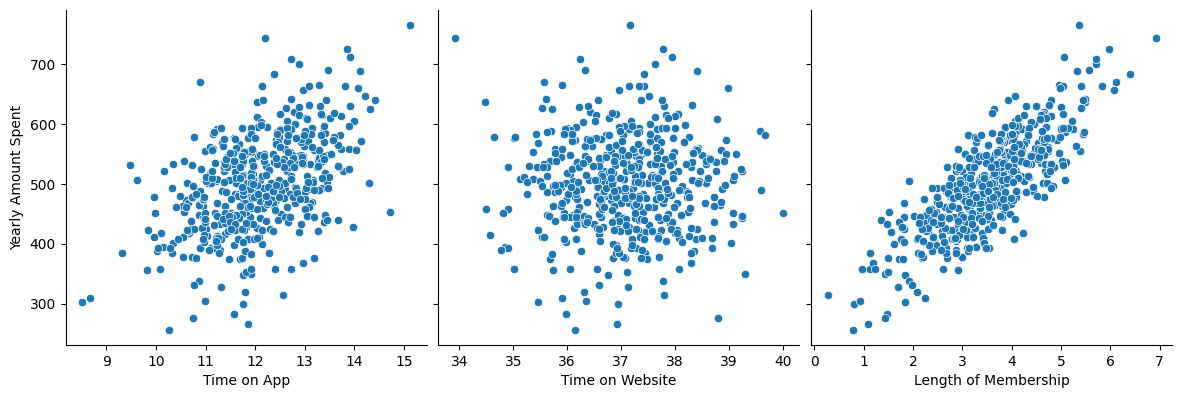

In [7]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

Gunakan pairplot untuk menampilkan hubungan antara variabel bebas dan variabel target dalam bentuk scatter plot.

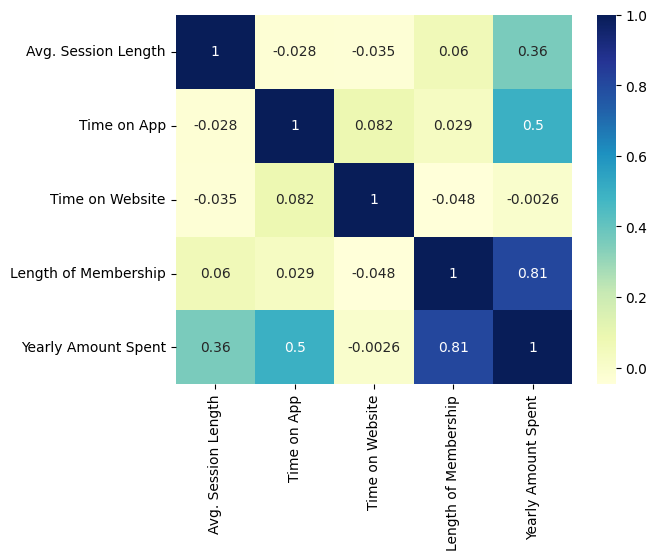

In [10]:
# Visualisasi korelasi dengan heatmap
sns.heatmap(
    data.corr(numeric_only=True),
    cmap="YlGnBu",
    annot=True
)

plt.show()

Regresi Linier

In [11]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

Pisahkan variabel bebas (X) dan variabel target (y).

In [12]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

Lakukan training model regresi linier menggunakan library StatsModels. Tambahkan konstanta (intercept) ke variabel bebas.

In [13]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

Visualisasikan garis regresi pada data latih.

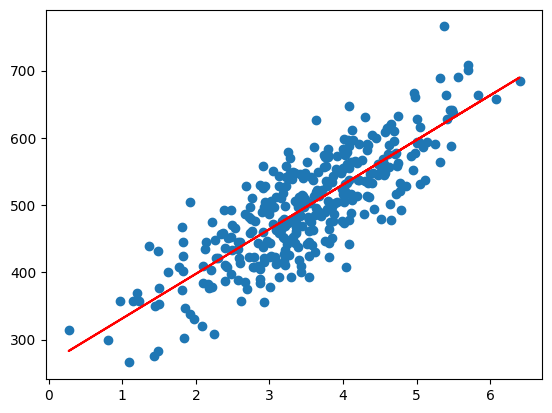

In [14]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

Analisis Residual

In [15]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

Lakukan prediksi nilai y dari data latih dan hitung residual (selisih antara nilai sebenarnya dan nilai prediksi).

/tmp/ipykernel_2900/594495671.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


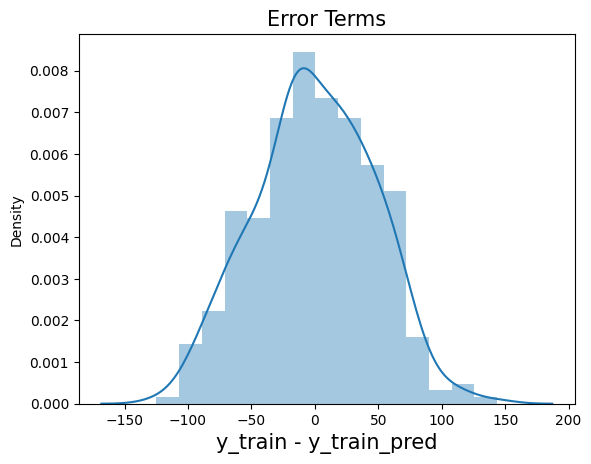

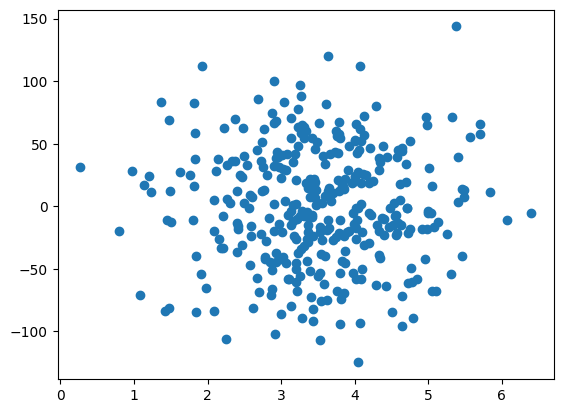

In [16]:
# Histogram residual
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

 Prediksi pada Data Uji dan Evaluasi Model

In [17]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

Lakukan prediksi pada data uji.

In [18]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)

Visualisasi Hasil

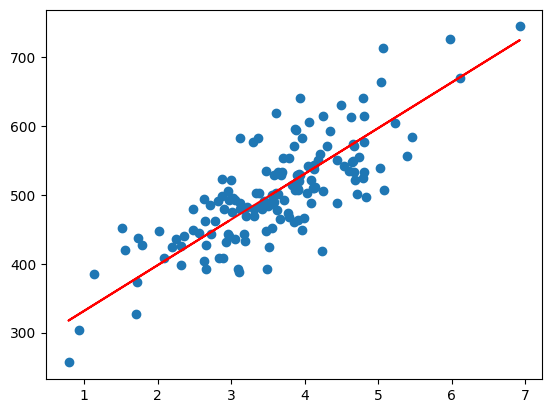

In [19]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

## Praktikum2

Mengimpor Library:

In [20]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Mengimpor Dataset:

In [21]:
# Mengimpor dataset (Pastikan Anda memiliki file CSV 'Posisi_gaji.csv' dalam direktori yang sama)
dataset = pd.read_csv('Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

Feature Scaling:

In [22]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

Fitting SVR ke Dataset:

In [23]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

Visualisasi Hasil SVR:

/tmp/ipykernel_2900/1841224750.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


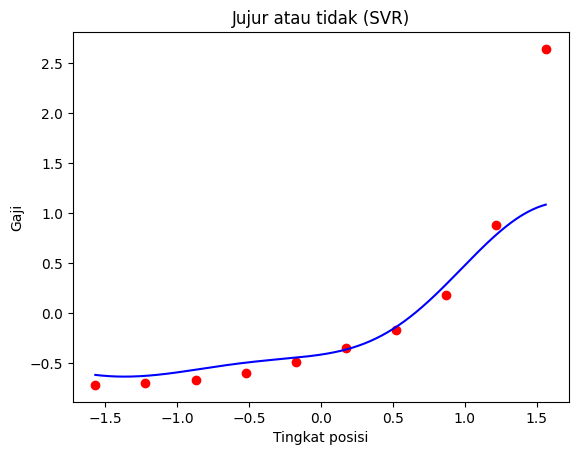

In [24]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

Prediksi Hasil:

In [25]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

Menampilkan Hasil:

In [28]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


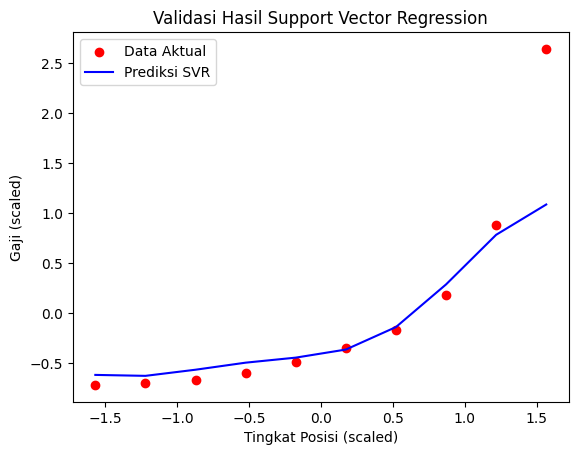

In [29]:
# Validasi hasil SVR
plt.scatter(X, y, color='red', label='Data Aktual')
plt.plot(X, regressor.predict(X), color='blue', label='Prediksi SVR')

plt.title('Validasi Hasil Support Vector Regression')
plt.xlabel('Tingkat Posisi (scaled)')
plt.ylabel('Gaji (scaled)')
plt.legend()
plt.show()

Evaluasi Model SVR

In [30]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


## Tugas Praktikum

**Tugas 1: Multiple Linear Regression**

Siapkan dataset dan library

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

Baca dataset

In [32]:
data = pd.read_csv('/content/insurance.csv')

data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


Pemahaman terhadap data

In [33]:
print("Ukuran dataset:", data.shape)

data.info()

display(data.describe())

print("Data kosong:")
print(data.isnull().sum())

Ukuran dataset: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


Data kosong:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


Visualisasi data

a: Visualisasi hubungan usia dan biaya

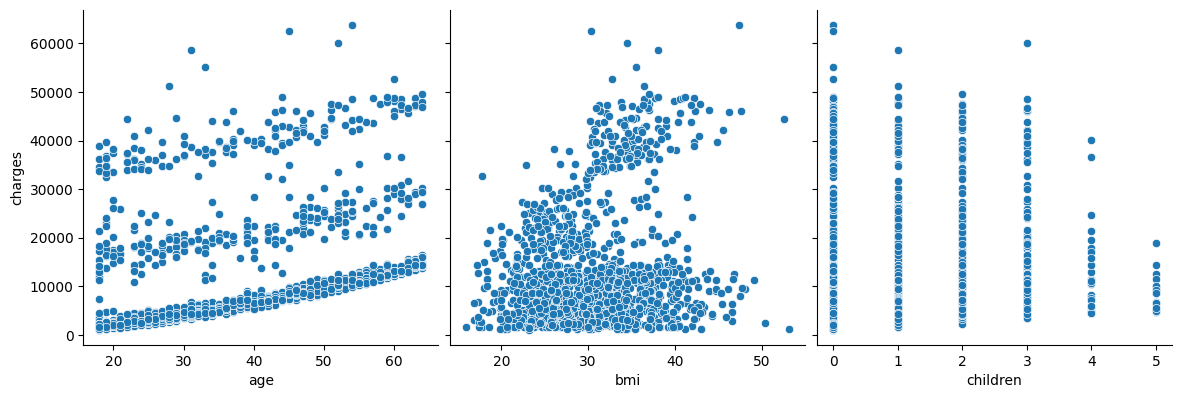

In [34]:
sns.pairplot(
    data,
    x_vars=['age', 'bmi', 'children'],
    y_vars=['charges'],
    height=4,
    aspect=1,
    kind='scatter'
)
plt.show()

b: Visualisasi korelasi variabel numerik

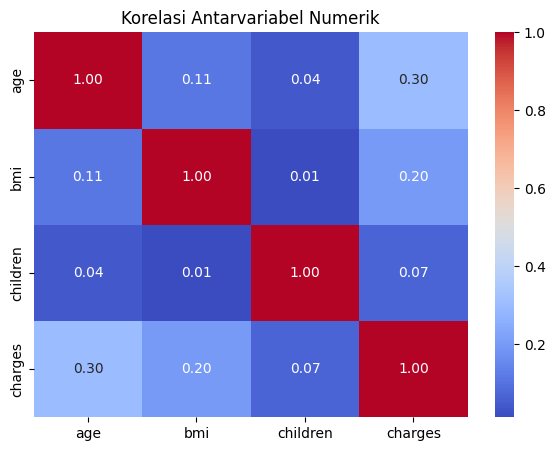

In [46]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    data.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Korelasi Antarvariabel Numerik')
plt.show()

Regresi linear berganda

In [36]:
# Memisahkan fitur dan target
X = data.drop(columns=['charges'])
y = data['charges']

# Mengubah fitur kategorikal menjadi numerik
X = pd.get_dummies(
    X,
    columns=['sex', 'smoker', 'region'],
    drop_first=True,
    dtype=int
)

display(X.head())

,age,bmi,children,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,0,1,0,0,1
1,18,33.770,1,1,0,0,1,0
2,28,33.000,3,1,0,0,1,0
3,33,22.705,0,1,0,1,0,0
4,32,28.880,0,1,0,1,0,0


bagi data menjadi data latih 70% dan data uji 30%

In [37]:
# Pembagian data latih dan data uji
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.7,
    test_size=0.3,
    random_state=100
)

print("Data latih:", X_train.shape)
print("Data uji:", X_test.shape)

Data latih: (936, 8)
Data uji: (402, 8)


In [38]:
# Training model Multiple Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

print("Model berhasil dilatih.")

Model berhasil dilatih.


Analisis residual:
hitung selisih antara nilai aktual dan nilai prediksi pada data latih.

In [39]:
# Prediksi data latih
y_train_pred = lr.predict(X_train)

# Menghitung residual
res = y_train - y_train_pred

Histogram residual:

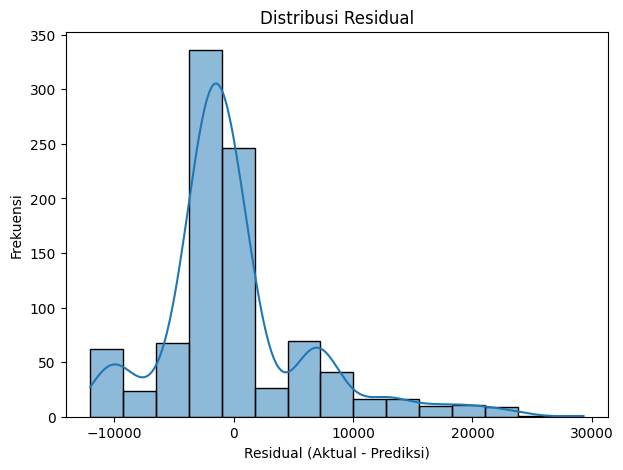

In [40]:
# Histogram residual
plt.figure(figsize=(7, 5))

sns.histplot(res, bins=15, kde=True)

plt.title('Distribusi Residual')
plt.xlabel('Residual (Aktual - Prediksi)')
plt.ylabel('Frekuensi')

plt.show()

Scatter plot residual:

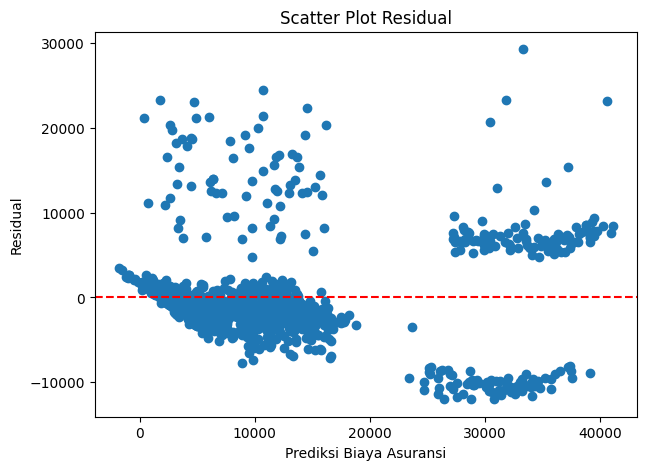

In [41]:
# Scatter plot residual
plt.figure(figsize=(7, 5))

plt.scatter(y_train_pred, res)
plt.axhline(y=0, color='red', linestyle='--')

plt.title('Scatter Plot Residual')
plt.xlabel('Prediksi Biaya Asuransi')
plt.ylabel('Residual')

plt.show()

Prediksi pada data uji dan evaluasi model

In [42]:
# Prediksi pada data uji
y_test_pred = lr.predict(X_test)

# Menghitung R-squared
r_squared = r2_score(y_test, y_test_pred)

print("R-squared:", r_squared)

R-squared: 0.77723105117331


In [43]:
mse = mean_squared_error(y_test, y_test_pred)
mae = mean_absolute_error(y_test, y_test_pred)

print("R-squared (R²):", round(r_squared, 4))
print("MSE:", round(mse, 2))
print("MAE:", round(mae, 2))

R-squared (R²): 0.7772
MSE: 32345536.75
MAE: 3943.24


Visualisasi hasil

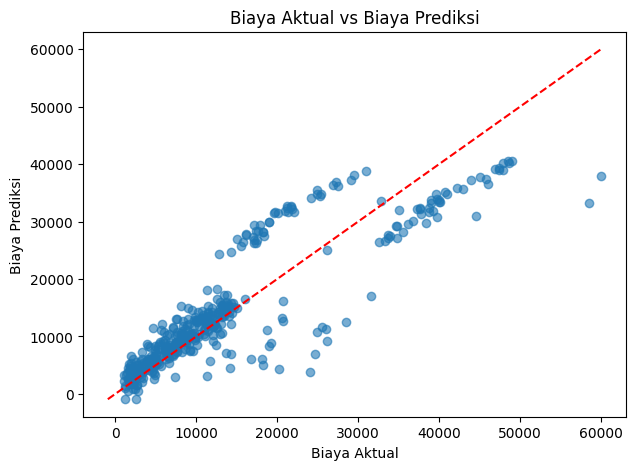

In [44]:
# Visualisasi hasil prediksi
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_test_pred, alpha=0.6)

nilai_min = min(y_test.min(), y_test_pred.min())
nilai_max = max(y_test.max(), y_test_pred.max())

plt.plot(
    [nilai_min, nilai_max],
    [nilai_min, nilai_max],
    color='red',
    linestyle='--'
)

plt.title('Biaya Aktual vs Biaya Prediksi')
plt.xlabel('Biaya Aktual')
plt.ylabel('Biaya Prediksi')

plt.show()

### Analisis Hasil

Berdasarkan hasil pengujian, model *Multiple Linear Regression* digunakan untuk memprediksi biaya asuransi berdasarkan beberapa faktor, yaitu usia, jenis kelamin, BMI, jumlah anak, status merokok, dan wilayah tempat tinggal.

Hasil evaluasi menunjukkan nilai **R² sebesar 0,7772**, yang berarti model dapat menjelaskan sekitar 77,72% variasi biaya asuransi pada data pengujian. Sementara itu, nilai **MSE sebesar 32.345.536,75** menunjukkan besarnya rata-rata kuadrat kesalahan prediksi. Nilai **MAE sebesar 3.943,24** berarti rata-rata selisih antara biaya asuransi yang diprediksi dan biaya sebenarnya sekitar 3.943,24 satuan biaya.

Dari hasil tersebut, model sudah dapat memprediksi biaya asuransi dengan cukup baik, tetapi hasil prediksinya belum sepenuhnya akurat. Masih terdapat perbedaan antara biaya yang diprediksi dan biaya sebenarnya. Oleh karena itu, model ini dapat digunakan untuk memperkirakan biaya asuransi, tetapi hasilnya tetap perlu dipahami sebagai perkiraan, bukan nilai yang pasti.